In [8]:
import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("../models/modelo_classification.keras")

with open("../models/thresholds.json") as f:
    best_thresholds = json.load(f)

In [10]:
IMG_SIZE = (224, 224)

FINAL_CLASSES = [
    "Diagonal crack",
    "Concrete spalling",
    "Corrosion",
    "Shear crack",
    "Flexural/rocking crack",
    "Debris",
    "Detachment crack",
]

FOLDER_PATH = "prueba"

Se encontraron 5 imágenes en 'prueba'



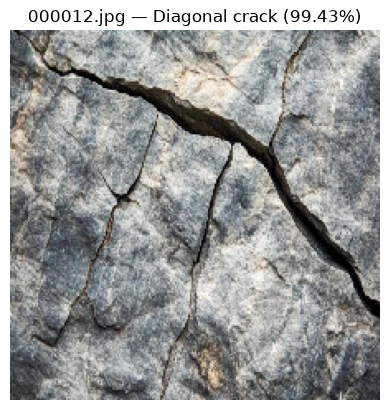

000012.jpg: Diagonal crack (99.43%)



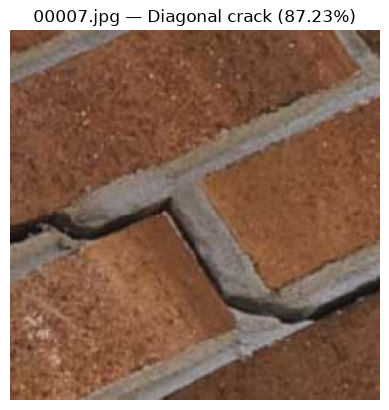

00007.jpg: Diagonal crack (87.23%)



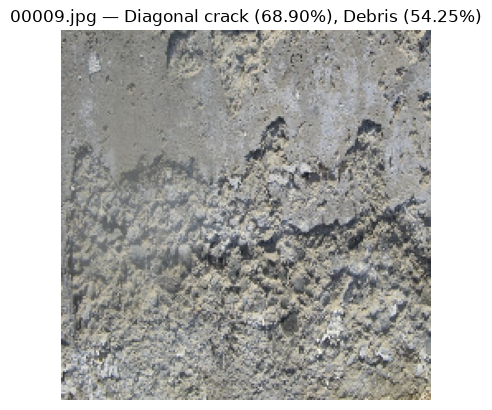

00009.jpg: Diagonal crack (68.90%), Debris (54.25%)



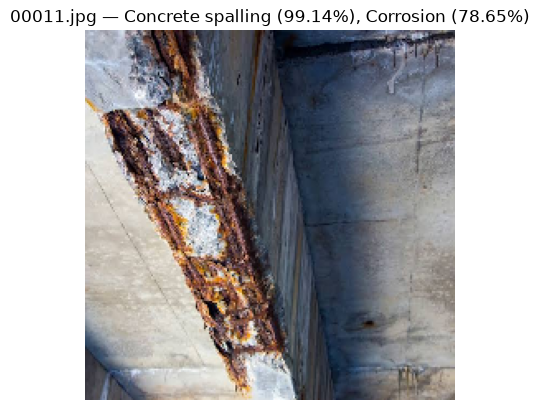

00011.jpg: Concrete spalling (99.14%), Corrosion (78.65%)



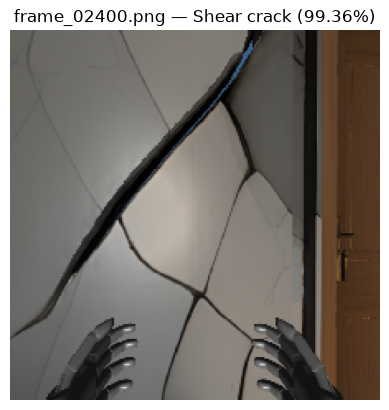

frame_02400.png: Shear crack (99.36%)



In [16]:
valid_extensions = (".jpg", ".jpeg", ".png")
image_files = [f for f in os.listdir(FOLDER_PATH) if f.lower().endswith(valid_extensions)]

print(f"Se encontraron {len(image_files)} imágenes en '{FOLDER_PATH}'\n")

for filename in image_files:
    image_path = os.path.join(FOLDER_PATH, filename)

    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    probs = model.predict(img_array, verbose=0)[0]
    detectados = [
        (FINAL_CLASSES[i], probs[i])
        for i in range(len(FINAL_CLASSES))
        if probs[i] > best_thresholds[FINAL_CLASSES[i]]
    ]
    detectados.sort(key=lambda x: x[1], reverse=True)
    label = ", ".join(f"{c} ({p:.2%})" for c, p in detectados) if detectados else "sin daños detectados"

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{filename} — {label}")
    plt.show()

    print(f"{filename}: {label}\n")